# Laboratorium 3 — Własny mini-zbiór obrazów i potok danych (spodnie vs bluzy)



Układ plików (VS Code: folder obok notatnika):
```
dane/
├── spodnie/   (≥30 zdjęć)
└── bluzy/     (≥30 zdjęć)
```

## 0. Instalacja i środowisko

In [5]:
#%pip install -q torch torchvision opencv-python-headless matplotlib pillow pandas

In [ ]:
import os, sys, time, shutil, random, zipfile
from collections import Counter
import numpy as np
import pandas as pd
import cv2
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from PIL import Image
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__,
      "| OpenCV:", cv2.__version__, "| urządzenie:", device)

IN_COLAB = "google.colab" in sys.modules
print("Colab:", IN_COLAB)

ROOT = "dane"
print("ROOT =", os.path.abspath(ROOT), "| istnieje:", os.path.isdir(ROOT))

PyTorch: 2.14.1+cpu | torchvision: 0.29.1+cpu | OpenCV: 5.0.0 | urządzenie: cpu
Colab: False
ROOT = c:\Users\macze\OneDrive\Pulpit\sprawozdanie3\dane | istnieje: True


In [ ]:
if IN_COLAB:
    USE_DRIVE = True
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        ROOT = "/content/drive/MyDrive/dane"
    else:
        with zipfile.ZipFile("dane.zip") as z: z.extractall(".")
        ROOT = "dane"
print("ROOT =", os.path.abspath(ROOT))

ROOT = c:\Users\macze\OneDrive\Pulpit\sprawozdanie3\dane


## 1. Zbiór w układzie ImageFolder — kontrola i balans klas

In [ ]:
EXPECTED = ["bluzy", "spodnie"]
EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

print("Zawartość ROOT:", sorted(os.listdir(ROOT)))
ds_all = datasets.ImageFolder(ROOT)
print("ds.classes       :", ds_all.classes)
print("class_to_idx     :", ds_all.class_to_idx)
assert ds_all.classes == EXPECTED, (
    f"Nieoczekiwane klasy {ds_all.classes}! Usuń z '{ROOT}' foldery typu __MACOSX / .ipynb_checkpoints.")
cnt = Counter(ds_all.targets)
print("Counter(targets) :", {ds_all.classes[k]: v for k, v in sorted(cnt.items())})
assert min(cnt.values()) >= 30, "Potrzeba min. 30 obrazów na klasę"
print(f"Balans: najmniejsza klasa {min(cnt.values())}, największa {max(cnt.values())}")

sizes = [Image.open(p).size for p, _ in ds_all.samples]
ws, hs = zip(*sizes)
print(f"Rozmiary oryginałów: szer. {min(ws)}–{max(ws)} px, wys. {min(hs)}–{max(hs)} px")

Zawartość ROOT: ['bluzy', 'spodnie']
ds.classes       : ['bluzy', 'spodnie']
class_to_idx     : {'bluzy': 0, 'spodnie': 1}
Counter(targets) : {'bluzy': 31, 'spodnie': 30}
Balans: najmniejsza klasa 30, największa 31


Rozmiary oryginałów: szer. 300–2772 px, wys. 301–3624 px


## 2. Podział na część treningową i walidacyjną (80/20)

Dzielimy **fizycznie** na foldery `dane_split/train/<klasa>` i `dane_split/val/<klasa>`, dzięki czemu każdą część wczytuje osobny `ImageFolder` z własnym potokiem transformacji. Podział jest **warstwowy** (80/20 w każdej klasie) i powtarzalny (`SEED`).

In [9]:
SPLIT = "dane_split"
VAL_FRAC = 0.2
if os.path.isdir(SPLIT): shutil.rmtree(SPLIT)

rng = random.Random(SEED)
for ci, cname in enumerate(ds_all.classes):
    files = sorted(p for p, t in ds_all.samples if t == ci)
    rng.shuffle(files)
    n_val = max(1, round(VAL_FRAC * len(files)))
    parts = {"val": files[:n_val], "train": files[n_val:]}
    for part, fl in parts.items():
        os.makedirs(f"{SPLIT}/{part}/{cname}", exist_ok=True)
        for f in fl:
            shutil.copy2(f, f"{SPLIT}/{part}/{cname}/{os.path.basename(f)}")
print("Utworzono:", SPLIT)

Utworzono: dane_split


## 3. Dwa potoki transformacji

**Ewaluacyjny** (walidacja): tylko `Resize` → `ToTensor` → `Normalize`. **Treningowy**: to samo + augmentacje.

Uzasadnienie, dlaczego augmentacje **nie zmieniają klasy** (spodnie/bluza):
- `RandomHorizontalFlip` — lustrzane odbicie spodni lub bluzy nadal jest spodniami lub bluzą (ubranie jest z grubsza symetryczne, a o klasie decyduje kształt, nie strona).
- `RandomRotation(15)` — niewielki obrót odpowiada lekko przekrzywionemu zdjęciu; kształt (nogawki vs rękawy i kaptur) pozostaje rozpoznawalny.
- `ColorJitter(brightness, contrast)` — zmiana oświetlenia nie zmienia rodzaju ubrania. Celowo **nie** zmieniamy odcienia (`hue`), bo kolor jest cechą konkretnego egzemplarza i nie powinien być sztucznie zaburzany.
- Nie używamy `RandomVerticalFlip` ani dużych obrotów — odwrócone do góry nogami spodnie wyglądałyby jak bluza z nogawkami/rękawami na opak i mogłyby zmylić zadanie.

In [10]:
IMG_SIZE = 128
MEAN, STD = [0.5]*3, [0.5]*3

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
print("Potok ewaluacyjny:\n", eval_tf)
print("Potok treningowy:\n", train_tf)

Potok ewaluacyjny:
 Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)
Potok treningowy:
 Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
)


## 4. ImageFolder + DataLoader

Trening: `shuffle=True` + potok treningowy. Walidacja: `shuffle=False` + potok ewaluacyjny. `num_workers=0`, żeby komunikaty błędów były czytelne.

In [11]:
train_ds = datasets.ImageFolder(f"{SPLIT}/train", transform=train_tf)
val_ds   = datasets.ImageFolder(f"{SPLIT}/val",   transform=eval_tf)
assert train_ds.classes == val_ds.classes == EXPECTED
assert train_ds.class_to_idx == val_ds.class_to_idx

BATCH = 16
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=0)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=0)
print("train:", len(train_ds), "obrazów,", len(train_dl), "paczek | val:", len(val_ds), "obrazów,", len(val_dl), "paczek")

train: 49 obrazów, 4 paczek | val: 12 obrazów, 1 paczek


## 5. Statystyki zbioru (tabela)

In [12]:
ct, cv_ = Counter(train_ds.targets), Counter(val_ds.targets)
stats = pd.DataFrame({
    "klasa": train_ds.classes,
    "indeks": [train_ds.class_to_idx[c] for c in train_ds.classes],
    "train": [ct[i] for i in range(len(train_ds.classes))],
    "val":   [cv_[i] for i in range(len(train_ds.classes))],
})
stats["razem"] = stats["train"] + stats["val"]
stats.loc[len(stats)] = ["SUMA", "-", stats.train.sum(), stats.val.sum(), stats.razem.sum()]
display(stats) if "display" in globals() else print(stats.to_string(index=False))

x0, _ = train_ds[0]
print("Liczba klas        :", len(train_ds.classes))
print("Rozmiar tensora    :", tuple(x0.shape), "= [C, H, W]")
print("class_to_idx       :", train_ds.class_to_idx)

  klasa indeks  train  val  razem
  bluzy      0     25    6     31
spodnie      1     24    6     30
   SUMA      -     49   12     61
Liczba klas        : 2
Rozmiar tensora    : (3, 128, 128) = [C, H, W]
class_to_idx       : {'bluzy': 0, 'spodnie': 1}


## 6. Audyt jednej paczki

Kształt, typ i zakres wartości tensora oraz etykiety. Po `Normalize([0.5],[0.5])` wartości powinny leżeć w [-1, 1].

kształt paczki : (16, 3, 128, 128) = [B, C, H, W]
dtype obrazów  : torch.float32 | dtype etykiet: torch.int64
zakres wartości: min=-1.000, max=1.000, średnia=0.285
etykiety       : [0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0]
nazwy klas     : ['bluzy', 'spodnie', 'spodnie', 'spodnie', 'spodnie', 'spodnie', 'bluzy', 'spodnie', 'bluzy', 'spodnie', 'bluzy', 'spodnie', 'bluzy', 'bluzy', 'bluzy', 'bluzy']


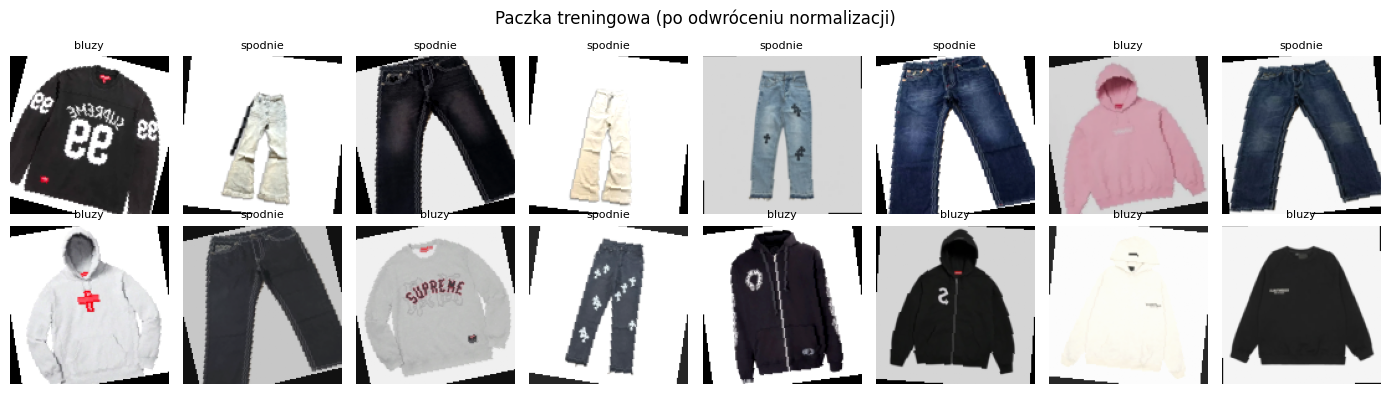

In [ ]:
xb, yb = next(iter(train_dl))
print("kształt paczki :", tuple(xb.shape), "= [B, C, H, W]")
print("dtype obrazów  :", xb.dtype, "| dtype etykiet:", yb.dtype)
print(f"zakres wartości: min={xb.min():.3f}, max={xb.max():.3f}, średnia={xb.mean():.3f}")
print("etykiety       :", yb.tolist())
print("nazwy klas     :", [train_ds.classes[i] for i in yb.tolist()])
assert xb.shape[1:] == (3, IMG_SIZE, IMG_SIZE) and xb.dtype == torch.float32
assert -1.0001 <= xb.min() and xb.max() <= 1.0001

def denorm(t):
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t*s + m).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(train_ds.classes[lb], fontsize=8); ax.axis("off")
plt.suptitle("Paczka treningowa (po odwróceniu normalizacji)"); plt.tight_layout(); plt.show()

### Podgląd wariantów augmentacji jednego obrazu

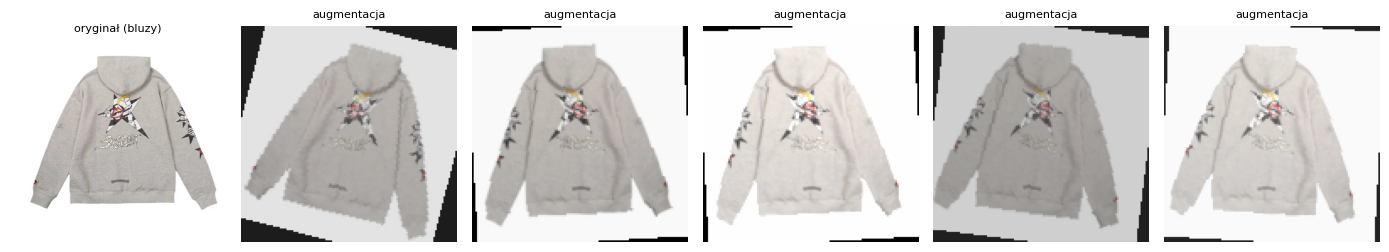

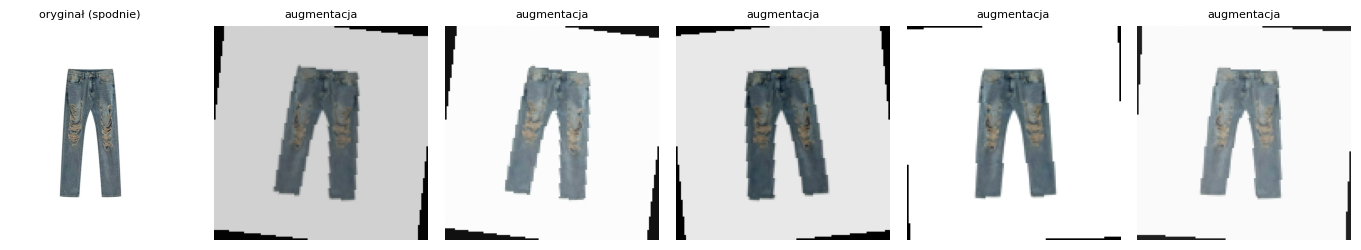

In [14]:
for cls in train_ds.classes:
    path = next(p for p, lb in train_ds.samples if train_ds.classes[lb] == cls)
    raw = Image.open(path).convert("RGB")
    fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
    axes[0].imshow(raw); axes[0].set_title(f"oryginał ({cls})", fontsize=8); axes[0].axis("off")
    for ax in axes[1:]:
        ax.imshow(denorm(train_tf(raw))); ax.set_title("augmentacja", fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

## 7. Wideo jako sekwencja klatek

In [30]:
VIDEO = "moj_film.mp4"

cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), f"Nie można otworzyć {VIDEO}"
FPS   = cap.get(cv2.CAP_PROP_FPS)
TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
DURATION = TOTAL / FPS
print(f"Plik: {VIDEO} | FPS: {FPS:.2f} | liczba klatek: {TOTAL} | czas trwania: {DURATION:.2f} s")

INTERVAL_S = 0.5
EVERY = max(1, round(FPS * INTERVAL_S))
print(f"Próbkowanie: co {EVERY}. klatkę = co {EVERY/FPS:.2f} s -> ok. {TOTAL//EVERY} obrazów")

Plik: moj_film.mp4 | FPS: 25.00 | liczba klatek: 295 | czas trwania: 11.80 s
Próbkowanie: co 12. klatkę = co 0.48 s -> ok. 24 obrazów


Odczytano 25 klatek (cv2) w 10.715 s | dtype=uint8, shape=(3840, 2160, 3) (H,W,C)


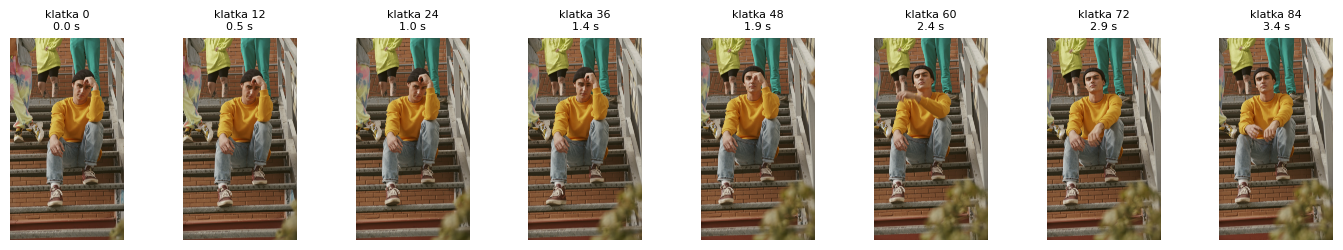

In [24]:
def read_frames(path, every=10):
    cap = cv2.VideoCapture(path)
    out, idxs, i = [], [], 0
    while True:
        ok, bgr = cap.read()
        if not ok: break
        if i % every == 0:
            out.append(bgr); idxs.append(i)
        i += 1
    cap.release()
    return out, idxs

t0 = time.perf_counter()
frames_bgr, frame_idx = read_frames(VIDEO, EVERY)
print(f"Odczytano {len(frames_bgr)} klatek (cv2) w {time.perf_counter()-t0:.3f} s | dtype={frames_bgr[0].dtype}, shape={frames_bgr[0].shape} (H,W,C)")

fig, axes = plt.subplots(1, min(8, len(frames_bgr)), figsize=(14, 2.6))
for ax, bgr, i in zip(np.atleast_1d(axes), frames_bgr, frame_idx):
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax.set_title(f"klatka {i}\n{i/FPS:.1f} s", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

### Dowód konwersji BGR → RGB
OpenCV zwraca kanały w kolejności B, G, R. `imshow` (matplotlib) oczekuje RGB, więc bez konwersji czerwień i błękit są zamienione.

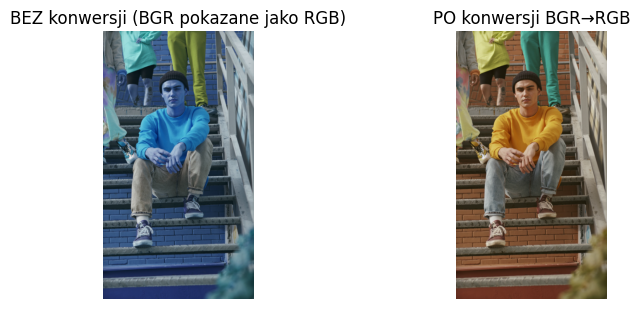

piksel (środek) przed: [49 62 97] (B,G,R) | po: [97 62 49] (R,G,B)


In [25]:
bgr = frames_bgr[len(frames_bgr)//2]
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].imshow(bgr); axes[0].set_title("BEZ konwersji (BGR pokazane jako RGB)"); axes[0].axis("off")
axes[1].imshow(rgb); axes[1].set_title("PO konwersji BGR→RGB"); axes[1].axis("off")
plt.tight_layout(); plt.show()

y, x = bgr.shape[0]//2, bgr.shape[1]//2
print("piksel (środek) przed:", bgr[y, x], "(B,G,R) | po:", rgb[y, x], "(R,G,B)")
assert (bgr[..., ::-1] == rgb).all()

## 8. Wyciek danych między treningiem a walidacją (wideo)

Poniżej podział czasowy wybranych klatek.

In [ ]:
n = len(frame_idx)
cut = int(0.8 * n)
GAP = 1
train_frames = frame_idx[:cut]
val_frames   = frame_idx[cut + GAP:]
print(f"train: klatki {train_frames[0]}–{train_frames[-1]} ({len(train_frames)}) | "
      f"val: klatki {val_frames[0]}–{val_frames[-1]} ({len(val_frames)})")
assert max(train_frames) < min(val_frames)

train: klatki 0–228 (20) | val: klatki 252–288 (4)


## 9. Zakres dodatkowy

### 9a. Wpływ parametru próbkowania `every`

 every  odstęp [s]  liczba obrazów  śr. różnica sąsiednich klatek
     1        0.04             295                           5.54
     5        0.20              59                          16.86
    15        0.60              20                          28.10
    30        1.20              10                          32.50


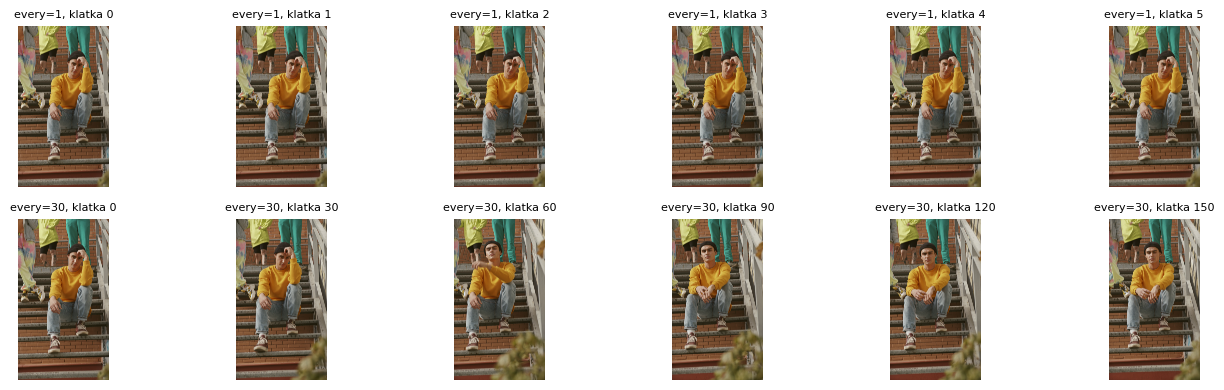

In [28]:
rows = []
for ev in [1, 5, 15, 30]:
    fr, ix = read_frames(VIDEO, ev)
    g = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY).astype(float) for f in fr]
    div = np.mean([np.abs(a-b).mean() for a, b in zip(g[:-1], g[1:])]) if len(g) > 1 else float("nan")
    rows.append({"every": ev, "odstęp [s]": round(ev/FPS, 3), "liczba obrazów": len(fr), "śr. różnica sąsiednich klatek": round(div, 2)})
print(pd.DataFrame(rows).to_string(index=False))

fr1, _ = read_frames(VIDEO, 1)
fig, axes = plt.subplots(2, 6, figsize=(14, 4))
for ax, f, lab in zip(axes[0], fr1[:6], range(6)):
    ax.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)); ax.set_title(f"every=1, klatka {lab}", fontsize=8); ax.axis("off")
for ax, k in zip(axes[1], range(0, 6*30, 30)):
    if k < len(fr1):
        ax.imshow(cv2.cvtColor(fr1[k], cv2.COLOR_BGR2RGB)); ax.set_title(f"every=30, klatka {k}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

### 9b. Test dymny potoku
Przepuszczamy kilka paczek przez prostą sieć (bez treningu), by sprawdzić, że kształty i typy pasują do modelu i strata jest skończona.

In [29]:
import torch.nn as nn
model = nn.Sequential(
    nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(),
    nn.Linear(8, len(train_ds.classes)),
).to(device).eval()
loss_fn = nn.CrossEntropyLoss()

for name, dl in [("train", train_dl), ("val", val_dl)]:
    for bi, (x, y) in enumerate(dl):
        with torch.no_grad():
            out = model(x.to(device)); loss = loss_fn(out, y.to(device))
        print(f"{name} paczka {bi}: wejście {tuple(x.shape)} -> wyjście {tuple(out.shape)} | strata {loss.item():.3f}")
        assert out.shape == (x.shape[0], len(train_ds.classes)) and torch.isfinite(loss)
        if bi == 1: break
print("Test dymny OK")

train paczka 0: wejście (16, 3, 128, 128) -> wyjście (16, 2) | strata 0.694
train paczka 1: wejście (16, 3, 128, 128) -> wyjście (16, 2) | strata 0.700
val paczka 0: wejście (12, 3, 128, 128) -> wyjście (12, 2) | strata 0.696
Test dymny OK
